# Credit Card Fraud Detection: Traditional Machine Learning vs. Deep Learning

## 1. Project Overview

This project investigates the effectiveness of traditional machine learning algorithms and deep learning models in detecting fraudulent credit card transactions. The study uses a publicly available dataset containing real transaction records, with fraudulent transactions representing a small minority of observations.

The project compares model performance, investigates the impact of class imbalance and hyperparameter tuning, and evaluates the models using metrics appropriate for binary classification.

## Research Question

How effectively can traditional machine learning and deep learning models detect fraudulent credit card transactions in a highly imbalanced dataset, and how do their performances compare?

In [48]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [49]:

from pathlib import Path

# Main project directory in Google Drive
PROJECT_DIR = Path(
    "/content/drive/MyDrive/ML_Summative_Credit_Card_Fraud"
)

# Subfolders for organized project files
FIGURES_DIR = PROJECT_DIR / "figures"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [FIGURES_DIR, RESULTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders ready!")
print("Project location:", PROJECT_DIR)


Project folders ready!
Project location: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud


In [50]:

import matplotlib.pyplot as plt

def save_figure(filename, dpi=300):
    """Save the current Matplotlib figure to Google Drive."""
    path = FIGURES_DIR / filename

    plt.savefig(
        path,
        dpi=dpi,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Figure saved to: {path}")


In [51]:
import pandas as pd
from pathlib import Path

path = Path("/content/creditcard.csv")

print("File size:", round(path.stat().st_size / (1024**2), 2), "MB")

df = pd.read_csv(path)

print("Shape:", df.shape)
print("\nClass distribution:")
print(df["Class"].value_counts(dropna=False))
print("\nMissing values:", df.isnull().sum().sum())

File size: 143.84 MB
Shape: (284807, 31)

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Missing values: 0


## 2. Exploratory Data Analysis

Exploratory data analysis is performed to understand the dataset's structure, feature distributions, class imbalance, and data quality before preprocessing and model development. Particular attention is given to the distribution of fraudulent transactions because the minority class is critical to the project's objective.

In [52]:
# Dataset overview
print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes.value_counts())

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values per column:")
print(df.isnull().sum().sum())

Dataset shape: (284807, 31)

Data types:


,count
float64,30
int64,1



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.487313e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.556467e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.213481e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.406331e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995



Duplicate rows: 1081

Missing values per column:
0


Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Class percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64
Figure saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/Distribution of legitimate and fraudulent transactions.png


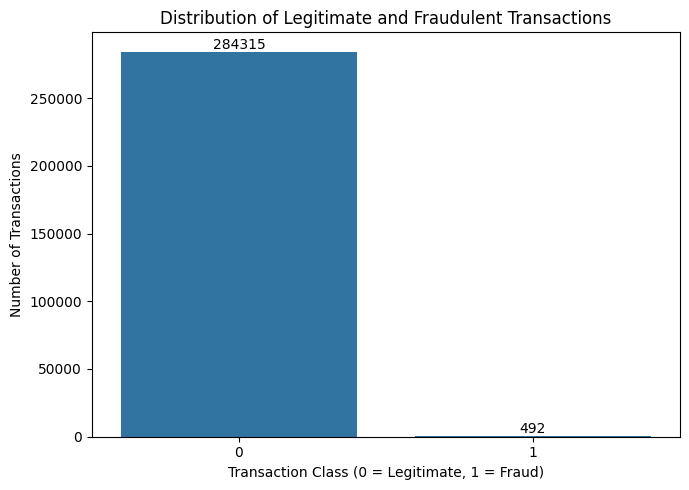

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(
    normalize=True
).sort_index() * 100

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(4))

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    x=class_counts.index.astype(str),
    y=class_counts.values
)

ax.set_title("Distribution of Legitimate and Fraudulent Transactions")
ax.set_xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
ax.set_ylabel("Number of Transactions")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

save_figure(filename="Distribution of legitimate and fraudulent transactions.png")
plt.tight_layout()
plt.show()

Figure saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/Transaction Amount Distributions by Class


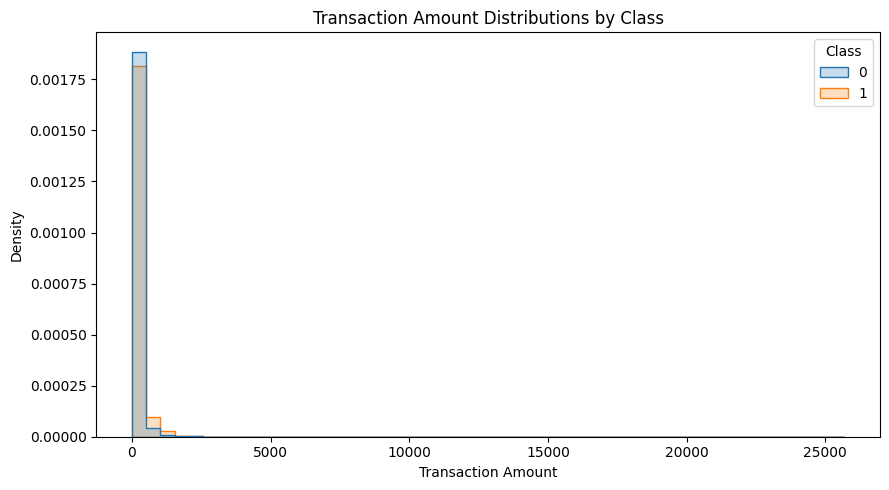

In [54]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Amount",
    hue="Class",
    bins=50,
    element="step",
    stat="density",
    common_norm=False
)

save_figure(filename="Transaction Amount Distributions by Class")
plt.title("Transaction Amount Distributions by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

### 2.1 Duplicate Record Investigation

Exact duplicate records are examined before preprocessing. Duplicate rows may affect model evaluation if identical observations appear in both training and test sets. However, identical transaction attributes do not automatically prove that the records are erroneous, so their class distribution and frequency are investigated before deciding whether to remove them.

In [55]:
# Investigate exact duplicates without changing the dataset

duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask].copy()

print("Repeated rows, including first occurrences:",
      len(duplicate_rows))

print("\nRows beyond the first occurrence:",
      df.duplicated().sum())

print("\nClass distribution among repeated rows:")
print(duplicate_rows["Class"].value_counts(dropna=False))

print("\nClass distribution among rows beyond first occurrences:")
print(df.loc[df.duplicated(), "Class"].value_counts(dropna=False))

print("\nExamples of repeated records:")
display(duplicate_rows.head(10))

Repeated rows, including first occurrences: 1854

Rows beyond the first occurrence: 1081

Class distribution among repeated rows:
Class
0    1822
1      32
Name: count, dtype: int64

Class distribution among rows beyond first occurrences:
Class
0    1062
1      19
Name: count, dtype: int64

Examples of repeated records:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


Figure saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/Legigimate and Fraudulent Transactipns amounts


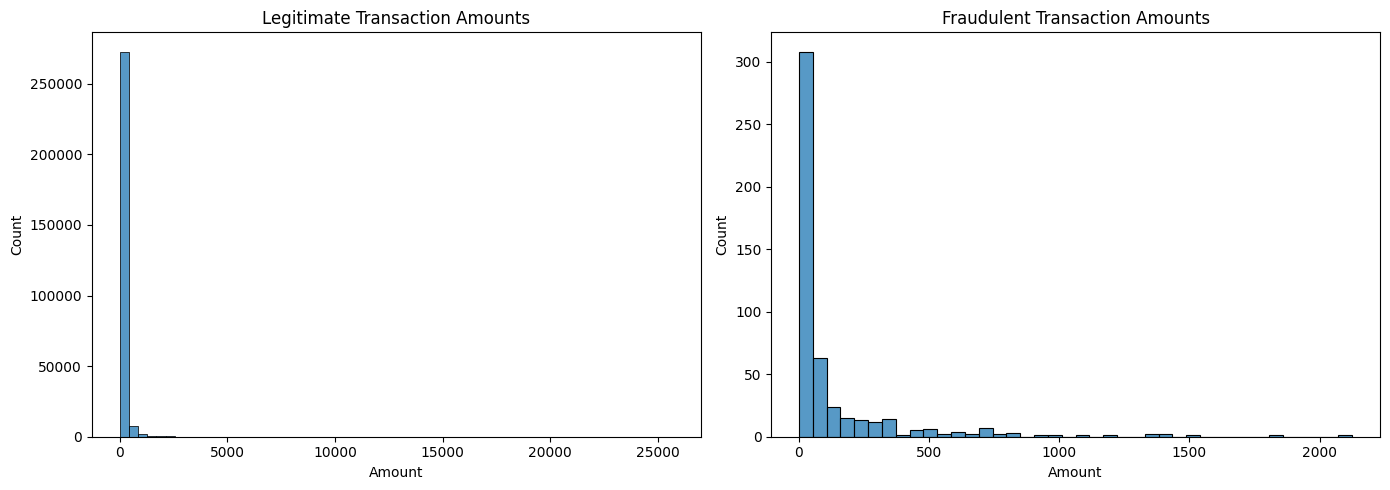

In [56]:
# Compare transaction amounts by class

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=60,
    ax=axes[0]
)
axes[0].set_title("Legitimate Transaction Amounts")
axes[0].set_xlabel("Amount")

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=40,
    ax=axes[1]
)
axes[1].set_title("Fraudulent Transaction Amounts")
axes[1].set_xlabel("Amount")

save_figure(filename="Legigimate and Fraudulent Transactipns amounts")
plt.tight_layout()
plt.show()

Features most negatively correlated with Class:


,Correlation
V17,-0.326481
V14,-0.302544
V12,-0.260593
V10,-0.216883
V16,-0.196539
V3,-0.192961
V7,-0.187257
V18,-0.111485
V1,-0.101347
V9,-0.097733


Features most positively correlated with Class:


,Correlation
V11,0.154876
V4,0.133447
V2,0.091289
V21,0.040413
V19,0.034783
V20,0.020090
V8,0.019875
V27,0.017580
V28,0.009536
Amount,0.005632


Figure saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/Feature Correlation withnFraud Class


<Figure size 640x480 with 0 Axes>

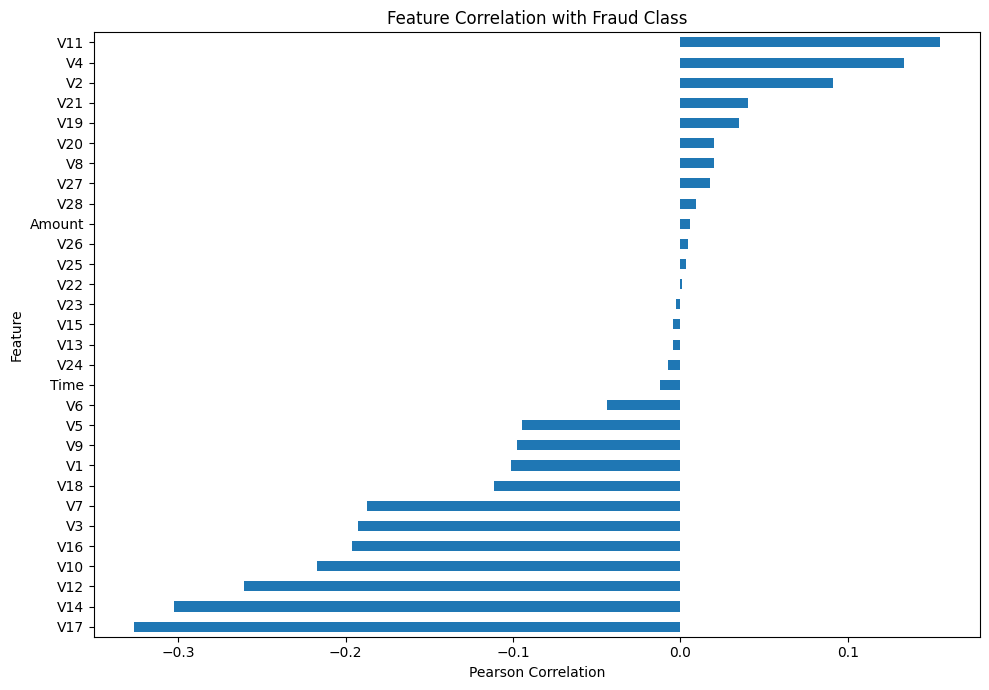

In [57]:
# Inspect the relationship between features and the target

correlations = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values()
)

print("Features most negatively correlated with Class:")
display(correlations.head(10).to_frame("Correlation"))

print("Features most positively correlated with Class:")
display(correlations.tail(10).sort_values(ascending=False).to_frame("Correlation"))

save_figure(filename="Feature Correlation withnFraud Class")
plt.figure(figsize=(10, 7))
correlations.sort_values().plot(kind="barh")
plt.title("Feature Correlation with Fraud Class")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Exploratory Data Analysis Findings

The dataset contains 284,807 transactions and 30 input features, alongside a binary target variable. It is highly imbalanced, with 284,315 legitimate transactions (99.8273%) and 492 fraudulent transactions (0.1727%). Consequently, accuracy alone would be an unsuitable measure of model performance.

The transaction amount distributions are strongly right-skewed, with most transactions concentrated at relatively low amounts and a small number of high-value transactions. The PCA-transformed features have means close to zero, while Time and Amount have different scales.

The initial inspection identified 1,081 rows beyond the first occurrence of exact duplicate records. These records will be investigated and handled in a separate modeling dataset, while the original raw dataset remains unchanged. Correlation analysis will be used as an exploratory tool rather than as the sole basis for feature selection.

In [58]:
from sklearn.model_selection import train_test_split

# Preserve df as the untouched raw dataset
df_model = df.drop_duplicates().copy()

print("Original dataset:", df.shape)
print("After removing exact duplicates:", df_model.shape)
print("Rows removed:", len(df) - len(df_model))

# Confirm target labels
print("\nTarget distribution after duplicate removal:")
print(df_model["Class"].value_counts())

Original dataset: (284807, 31)
After removing exact duplicates: (283726, 31)
Rows removed: 1081

Target distribution after duplicate removal:
Class
0    283253
1       473
Name: count, dtype: int64


In [59]:
# Separate features and target
X = df_model.drop(columns="Class")
y = df_model["Class"].astype(int)

# First: reserve 15% for final testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

# Second: reserve 15% of the full dataset for validation
# 0.17647 of the remaining 85% is approximately 15% of the full dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.17647,
    stratify=y_train_val,
    random_state=42
)

print("Training set:", X_train.shape, "| Fraud cases:", y_train.sum())
print("Validation set:", X_val.shape, "| Fraud cases:", y_val.sum())
print("Test set:", X_test.shape, "| Fraud cases:", y_test.sum())

print("\nFraud percentages:")
print("Train:", round(y_train.mean() * 100, 4), "%")
print("Validation:", round(y_val.mean() * 100, 4), "%")
print("Test:", round(y_test.mean() * 100, 4), "%")

Training set: (198608, 30) | Fraud cases: 331
Validation set: (42559, 30) | Fraud cases: 71
Test set: (42559, 30) | Fraud cases: 71

Fraud percentages:
Train: 0.1667 %
Validation: 0.1668 %
Test: 0.1668 %


In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val),
    columns=X_val.columns,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Scaled training data:", X_train_scaled.shape)
print("Scaled validation data:", X_val_scaled.shape)
print("Scaled test data:", X_test_scaled.shape)

Scaled training data: (198608, 30)
Scaled validation data: (42559, 30)
Scaled test data: (42559, 30)


Validation Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.98      0.99     42488
       Fraud       0.06      0.92      0.11        71

    accuracy                           0.98     42559
   macro avg       0.53      0.95      0.55     42559
weighted avg       1.00      0.98      0.99     42559

Validation ROC-AUC: 0.9767
Validation PR-AUC (Average Precision): 0.7217
Figure saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/Logistic Regression — Validation Confusion Matrix


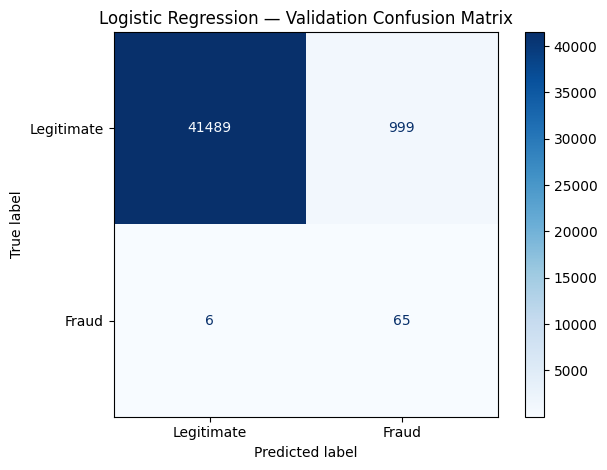

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

baseline_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

baseline_model.fit(X_train_scaled, y_train)

# Evaluate on validation data, not the test set
val_predictions = baseline_model.predict(X_val_scaled)
val_probabilities = baseline_model.predict_proba(X_val_scaled)[:, 1]

print("Validation Classification Report:")
print(classification_report(
    y_val,
    val_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("Validation ROC-AUC:", round(roc_auc_score(
    y_val, val_probabilities
), 4))

print("Validation PR-AUC (Average Precision):", round(
    average_precision_score(y_val, val_probabilities), 4
))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    display_labels=["Legitimate", "Fraud"],
    cmap="Blues",
    values_format="d"
)

save_figure(filename="Logistic Regression — Validation Confusion Matrix")
plt.title("Logistic Regression — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

### Traditional Machine Learning Model Comparison

Random Forest and Histogram-based Gradient Boosting are evaluated alongside Logistic Regression to investigate whether nonlinear decision boundaries improve fraud detection. Class imbalance is addressed during training using class weights or sample weights. All models are evaluated on the same validation set using fraud-class precision, recall, F1-score, ROC-AUC, and average precision.

In [62]:
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Histogram-based Gradient Boosting
hgb_model = HistGradientBoostingClassifier(
    max_iter=150,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    random_state=42
)

# Give the minority class greater weight during training
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

hgb_model.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

print("Random Forest and Gradient Boosting training complete.")

Random Forest and Gradient Boosting training complete.


In [63]:
models = {
    "Logistic Regression": baseline_model,
    "Random Forest": rf_model,
    "Hist Gradient Boosting": hgb_model
}

results = []
validation_probabilities = {}

for name, model in models.items():
    # Logistic Regression uses scaled data
    if name == "Logistic Regression":
        X_eval = X_val_scaled
    else:
        X_eval = X_val

    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    validation_probabilities[name] = probabilities

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(
            y_val, probabilities
        )
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,
Logistic Regression,0.0611,0.9155,0.1145,0.9767,0.7217
Random Forest,0.9355,0.8169,0.8722,0.9555,0.8593
Hist Gradient Boosting,0.5495,0.8592,0.6703,0.9751,0.7442


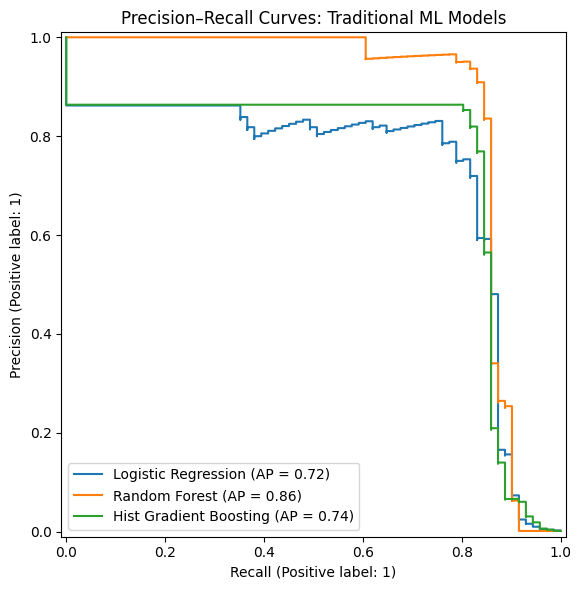

In [64]:
from sklearn.metrics import PrecisionRecallDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, probabilities in validation_probabilities.items():
    PrecisionRecallDisplay.from_predictions(
        y_val,
        probabilities,
        name=name,
        ax=plt.gca()
    )

plt.title("Precision–Recall Curves: Traditional ML Models")
plt.tight_layout()
plt.show()

In [65]:
# Save traditional ML comparison results
results_df.to_csv(
    RESULTS_DIR / "traditional_ml_comparison.csv",
    index=True
)

# Save the current precision-recall figure
plt.savefig(
    FIGURES_DIR / "traditional_ml_precision_recall.png",
    dpi=300,
    bbox_inches="tight"
)

print("Results and graph saved to Google Drive.")

Results and graph saved to Google Drive.


<Figure size 640x480 with 0 Axes>

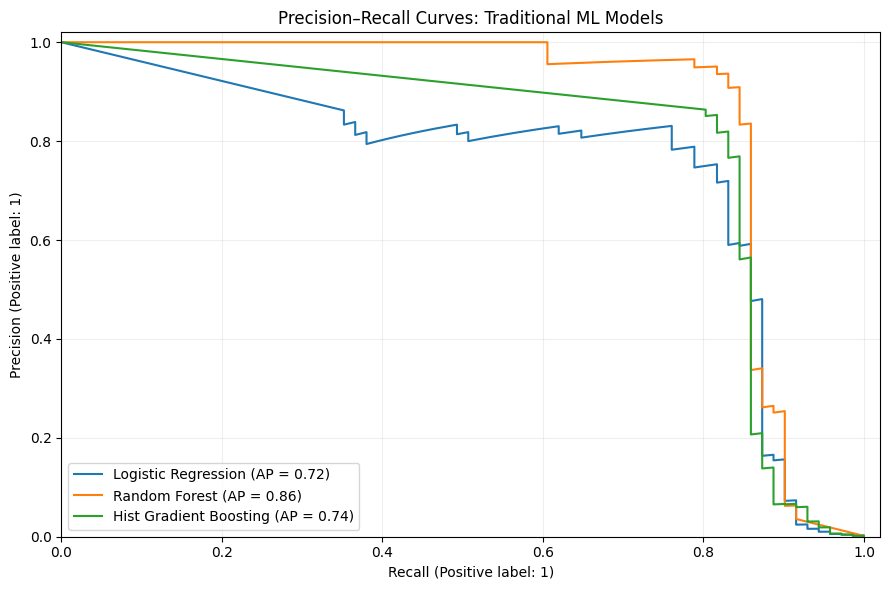

Saved to: /content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures/traditional_ml_precision_recall.png
File size: 182,809 bytes
Graph saved and basic file-size check passed.


In [66]:

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score
from pathlib import Path

# Make sure Drive is mounted and FIGURES_DIR exists
FIGURES_DIR = Path(
    "/content/drive/MyDrive/ML_Summative_Credit_Card_Fraud/figures"
)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Create a fresh figure rather than reusing an old one
fig, ax = plt.subplots(figsize=(9, 6))

for name, probabilities in validation_probabilities.items():
    precision, recall, _ = precision_recall_curve(
        y_val, probabilities
    )
    ap = average_precision_score(y_val, probabilities)

    ax.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.2f})"
    )

ax.set_title("Precision–Recall Curves: Traditional ML Models")
ax.set_xlabel("Recall (Positive label: 1)")
ax.set_ylabel("Precision (Positive label: 1)")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend(loc="best")
ax.grid(alpha=0.2)
fig.tight_layout()

# Save BEFORE displaying or closing the figure
graph_path = FIGURES_DIR / "traditional_ml_precision_recall.png"

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
    format="png"
)

plt.show()
plt.close(fig)

# Verify that the file was actually written
print(f"Saved to: {graph_path}")
print(f"File size: {graph_path.stat().st_size:,} bytes")

assert graph_path.stat().st_size > 10_000, (
    "The saved image is unexpectedly small. Check the figure and Drive."
)
print("Graph saved and basic file-size check passed.")


In [67]:
from sklearn.metrics import precision_recall_curve
import pandas as pd
import numpy as np

threshold_results = []

target_recall = 0.80

for name, probabilities in validation_probabilities.items():
    precision, recall, thresholds = precision_recall_curve(
        y_val, probabilities
    )

    # Each threshold corresponds to precision[:-1] and recall[:-1]
    valid = np.where(recall[:-1] >= target_recall)[0]

    if len(valid) == 0:
        print(f"{name}: No threshold meets the recall target.")
        continue

    # Among thresholds meeting the recall target,
    # select the one with the highest precision.
    best_idx = valid[np.argmax(precision[:-1][valid])]
    best_threshold = thresholds[best_idx]

    predictions = (probabilities >= best_threshold).astype(int)

    threshold_results.append({
        "Model": name,
        "Threshold": best_threshold,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results).set_index("Model")

display(threshold_df.round(4))

threshold_df.to_csv(
    RESULTS_DIR / "threshold_optimization.csv"
)

,Threshold,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9999,0.7532,0.8169,0.7838
Random Forest,0.5931,0.9508,0.8169,0.8788
Hist Gradient Boosting,0.9955,0.8636,0.8028,0.8321


In [68]:

from pathlib import Path
from datetime import datetime
import json

# Create one uniquely named folder per experiment
EXPERIMENT_ID = (
    "rf_tuning_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

EXPERIMENT_DIR = (
    Path("/content/drive/MyDrive/ML_Summative_Credit_Card/experiments")
    / EXPERIMENT_ID
)

EXPERIMENT_FIGURES = EXPERIMENT_DIR / "figures"
EXPERIMENT_RESULTS = EXPERIMENT_DIR / "results"
EXPERIMENT_MODELS = EXPERIMENT_DIR / "models"

for folder in [
    EXPERIMENT_FIGURES,
    EXPERIMENT_RESULTS,
    EXPERIMENT_MODELS
]:
    folder.mkdir(parents=True, exist_ok=True)

# Record experiment identity and purpose
metadata = {
    "experiment_id": EXPERIMENT_ID,
    "experiment_type": "Random Forest hyperparameter tuning",
    "dataset": "Kaggle Credit Card Fraud Detection",
    "selection_metric": "Average Precision",
    "evaluation_data": "Validation set",
    "random_seed": 42
}

with open(EXPERIMENT_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Experiment initialized:", EXPERIMENT_ID)
print("All experiment artifacts will be saved to:")
print(EXPERIMENT_DIR)


Experiment initialized: rf_tuning_20261017_201037
All experiment artifacts will be saved to:
/content/drive/MyDrive/ML_Summative_Credit_Card/experiments/rf_tuning_20261017_201037


In [69]:

import pandas as pd

threshold_results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Hist Gradient Boosting"
    ],
    "Threshold": [0.9999, 0.5931, 0.9955],
    "Precision": [0.7532, 0.9508, 0.8636],
    "Recall": [0.8169, 0.8169, 0.8028],
    "F1-score": [0.7838, 0.8788, 0.8321]
}).set_index("Model")

threshold_results_df.to_csv(
    RESULTS_DIR / "baseline_threshold_optimization.csv"
)

display(threshold_results_df)
print("Threshold optimization results saved to Google Drive.")


,Threshold,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9999,0.7532,0.8169,0.7838
Random Forest,0.5931,0.9508,0.8169,0.8788
Hist Gradient Boosting,0.9955,0.8636,0.8028,0.8321


Threshold optimization results saved to Google Drive.


In [70]:

from pathlib import Path
from datetime import datetime
import json

EXPERIMENT_ID = (
    "rf_tuning_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

EXPERIMENT_DIR = (
    Path("/content/drive/MyDrive/ML_Summative_Credit_Card/experiments")
    / EXPERIMENT_ID
)

EXPERIMENT_FIGURES = EXPERIMENT_DIR / "figures"
EXPERIMENT_RESULTS = EXPERIMENT_DIR / "results"
EXPERIMENT_MODELS = EXPERIMENT_DIR / "models"

for folder in [
    EXPERIMENT_FIGURES,
    EXPERIMENT_RESULTS,
    EXPERIMENT_MODELS
]:
    folder.mkdir(parents=True, exist_ok=True)

metadata = {
    "experiment_id": EXPERIMENT_ID,
    "experiment": "Random Forest hyperparameter tuning",
    "dataset": "Kaggle Credit Card Fraud Detection",
    "selection_metric": "Average Precision",
    "cross_validation": "2-fold stratified cross-validation",
    "random_seed": 42,
    "validation_threshold_for_initial_comparison": 0.5
}

with open(EXPERIMENT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Experiment:", EXPERIMENT_ID)
print("Saving all artifacts to:", EXPERIMENT_DIR)


Experiment: rf_tuning_20261017_201037
Saving all artifacts to: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/rf_tuning_20261017_201037


In [71]:

import numpy as np
import pandas as pd
import joblib
import json

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# Parameter combinations to explore
param_distributions = {
    "max_depth": [None, 12, 20],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.7],
    "class_weight": ["balanced_subsample"]
}

cv = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_distributions,
    n_iter=4,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=True
)

# Fit only on the training split
search.fit(X_train, y_train)

best_rf_model = search.best_estimator_

print("\nBest cross-validation Average Precision:",
      round(search.best_score_, 4))
print("\nBest parameters:")
print(search.best_params_)

# Save all search results
cv_results_df = pd.DataFrame(search.cv_results_)

cv_results_df.to_csv(
    EXPERIMENT_RESULTS / "cross_validation_results.csv",
    index=False
)

with open(
    EXPERIMENT_RESULTS / "best_hyperparameters.json", "w"
) as f:
    json.dump(search.best_params_, f, indent=4)

joblib.dump(
    best_rf_model,
    EXPERIMENT_MODELS / "best_random_forest.joblib"
)

print("\nCross-validation results and tuned model saved.")


Fitting 2 folds for each of 4 candidates, totalling 8 fits

Best cross-validation Average Precision: 0.8278

Best parameters:
{'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None, 'class_weight': 'balanced_subsample'}

Cross-validation results and tuned model saved.


,Threshold,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
Baseline Random Forest,0.5,0.9355,0.8169,0.8722,0.9555,0.8593
Tuned Random Forest,0.5,0.9355,0.8169,0.8722,0.9491,0.8618


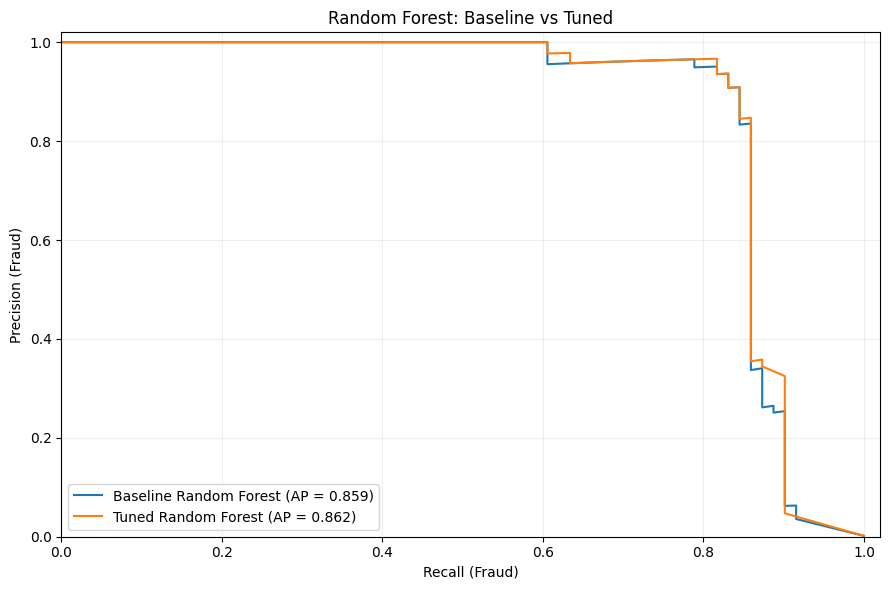


Experiment artifacts saved together:
Metrics: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/rf_tuning_20261017_201037/results
Graph: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/rf_tuning_20261017_201037/figures/random_forest_precision_recall.png
Model: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/rf_tuning_20261017_201037/models


In [72]:

# Predict fraud probabilities on the same validation set
baseline_probs = rf_model.predict_proba(X_val)[:, 1]
tuned_probs = best_rf_model.predict_proba(X_val)[:, 1]

probability_sets = {
    "Baseline Random Forest": baseline_probs,
    "Tuned Random Forest": tuned_probs
}

comparison_rows = []

for name, probs in probability_sets.items():
    preds = (probs >= 0.5).astype(int)

    comparison_rows.append({
        "Model": name,
        "Threshold": 0.5,
        "Precision": precision_score(
            y_val, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val, preds, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, preds, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, probs),
        "Average Precision": average_precision_score(y_val, probs)
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model")

display(comparison_df.round(4))

# Save the metrics
comparison_df.to_csv(
    EXPERIMENT_RESULTS / "baseline_vs_tuned_validation.csv"
)

# Plot precision-recall curves
fig, ax = plt.subplots(figsize=(9, 6))

for name, probs in probability_sets.items():
    precision, recall, _ = precision_recall_curve(y_val, probs)
    ap = average_precision_score(y_val, probs)

    ax.plot(recall, precision, label=f"{name} (AP = {ap:.3f})")

ax.set_title("Random Forest: Baseline vs Tuned")
ax.set_xlabel("Recall (Fraud)")
ax.set_ylabel("Precision (Fraud)")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()

graph_path = (
    EXPERIMENT_FIGURES / "random_forest_precision_recall.png"
)

fig.savefig(
    graph_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close(fig)

# Update metadata with the results from THIS run
metadata.update({
    "best_cv_average_precision": float(search.best_score_),
    "best_parameters": search.best_params_,
    "baseline_validation_average_precision": float(
        average_precision_score(y_val, baseline_probs)
    ),
    "tuned_validation_average_precision": float(
        average_precision_score(y_val, tuned_probs)
    )
})

with open(EXPERIMENT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("\nExperiment artifacts saved together:")
print("Metrics:", EXPERIMENT_RESULTS)
print("Graph:", graph_path)
print("Model:", EXPERIMENT_MODELS)


### Random Forest Hyperparameter Tuning

RandomizedSearchCV was used to explore four hyperparameter combinations with two-fold stratified cross-validation, using Average Precision as the selection metric because the dataset is highly imbalanced. The best configuration used `max_depth=None`, `min_samples_leaf=2`, `max_features='sqrt'`, and `class_weight='balanced_subsample'`, achieving a cross-validation Average Precision of 0.8278.

On the validation set, the tuned Random Forest achieved an Average Precision of 0.8618, compared with 0.8593 for the baseline model. Both models produced identical precision (0.9355), recall (0.8169), and F1-score (0.8722) at a threshold of 0.5. However, ROC-AUC decreased from 0.9555 to 0.9491. Overall, tuning produced a small improvement in Average Precision but did not substantially improve the model's threshold-based classification performance.

In [73]:
import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from datetime import datetime

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from tensorflow import keras
from tensorflow.keras import layers

# Reuse the project directory already defined in your notebook.
# If PROJECT_DIR is not defined, set it to your actual existing Drive folder.
PROJECT_DIR = Path("/content/drive/MyDrive/ML_Summative_Credit_Card")

EXPERIMENT_NAME = (
    "neural_network_" + datetime.now().strftime("%Y%m%d_%H%M%S")
)

EXPERIMENT_DIR = PROJECT_DIR / "experiments" / EXPERIMENT_NAME
EXPERIMENT_RESULTS = EXPERIMENT_DIR / "results"
EXPERIMENT_FIGURES = EXPERIMENT_DIR / "figures"
EXPERIMENT_MODELS = EXPERIMENT_DIR / "models"

for folder in [
    EXPERIMENT_RESULTS,
    EXPERIMENT_FIGURES,
    EXPERIMENT_MODELS
]:
    folder.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "experiment_name": EXPERIMENT_NAME,
    "model_type": "TensorFlow/Keras feedforward neural network",
    "dataset": "Credit Card Fraud Detection",
    "random_state": 42,
    "batch_size": 512,
    "epochs": 30,
    "learning_rate": 0.001,
    "early_stopping_patience": 5,
    "validation_split": "Existing validation set; test set remains untouched",
    "imbalance_handling": "Class weights",
    "input_features": int(X_train.shape[1])
}

with open(EXPERIMENT_RESULTS / "experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print("TensorFlow version:", tf.__version__)
print("Experiment folder:", EXPERIMENT_DIR)
print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Test features:", X_test.shape)
print("Experiment configuration saved.")

TensorFlow version: 2.21.0
Experiment folder: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/neural_network_20261017_202618
Training features: (198608, 30)
Validation features: (42559, 30)
Test features: (42559, 30)
Experiment configuration saved.


In [74]:
# Fit only on training data to prevent data leakage.
nn_scaler = StandardScaler()

X_train_nn = nn_scaler.fit_transform(X_train).astype(np.float32)
X_val_nn = nn_scaler.transform(X_val).astype(np.float32)
X_test_nn = nn_scaler.transform(X_test).astype(np.float32)

y_train_nn = np.asarray(y_train, dtype=np.float32)
y_val_nn = np.asarray(y_val, dtype=np.float32)
y_test_nn = np.asarray(y_test, dtype=np.int32)

# Save the fitted scaler so future predictions use the same transformation.
joblib.dump(
    nn_scaler,
    EXPERIMENT_MODELS / "neural_network_scaler.joblib"
)

print("Scaled training data:", X_train_nn.shape)
print("Scaled validation data:", X_val_nn.shape)
print("Scaled test data:", X_test_nn.shape)
print("Training fraud cases:", int(y_train_nn.sum()))
print("Validation fraud cases:", int(y_val_nn.sum()))
print("Test fraud cases:", int(y_test_nn.sum()))
print("Scaler saved.")

Scaled training data: (198608, 30)
Scaled validation data: (42559, 30)
Scaled test data: (42559, 30)
Training fraud cases: 331
Validation fraud cases: 71
Test fraud cases: 71
Scaler saved.


In [75]:
BATCH_SIZE = CONFIG["batch_size"]
AUTOTUNE = tf.data.AUTOTUNE

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train_nn, y_train_nn))
    .shuffle(
        buffer_size=min(len(X_train_nn), 50_000),
        seed=42,
        reshuffle_each_iteration=True
    )
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val_nn, y_val_nn))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test_nn, y_test_nn))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())

Training batches: 388
Validation batches: 84
Test batches: 84


In [76]:
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.astype(int)
)

CLASS_WEIGHTS = {
    int(class_label): float(weight)
    for class_label, weight in zip(classes, weights)
}

print("Class weights:", CLASS_WEIGHTS)

with open(EXPERIMENT_RESULTS / "class_weights.json", "w") as f:
    json.dump(CLASS_WEIGHTS, f, indent=4)

Class weights: {0: 0.5008346908617742, 1: 300.012084592145}


In [77]:
tf.keras.utils.set_random_seed(42)

nn_model = keras.Sequential([
    layers.Input(shape=(X_train_nn.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=CONFIG["learning_rate"]),
    loss="binary_crossentropy",
    metrics=[
        keras.metrics.AUC(name="roc_auc"),
        keras.metrics.AUC(curve="PR", name="pr_auc"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall")
    ]
)

nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,481 (17.50 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 192 (768.00 B)

In [78]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_pr_auc",
    mode="max",
    patience=CONFIG["early_stopping_patience"],
    restore_best_weights=True,
    verbose=1
)

start_time = time.time()

history = nn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=CONFIG["epochs"],
    class_weight=CLASS_WEIGHTS,
    callbacks=[early_stopping],
    verbose=1
)

training_seconds = time.time() - start_time

print(f"\nTraining time: {training_seconds / 60:.2f} minutes")

# Save the trained model and training history.
nn_model.save(EXPERIMENT_MODELS / "neural_network.keras")

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    EXPERIMENT_RESULTS / "training_history.csv",
    index=False
)

CONFIG["actual_epochs"] = len(history.history["loss"])
CONFIG["training_seconds"] = round(training_seconds, 2)

with open(EXPERIMENT_RESULTS / "experiment_config.json", "w") as f:
    json.dump(CONFIG, f, indent=4)

print("Model, training history, and updated configuration saved.")

Epoch 1/30
388/388 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - loss: 0.3381 - pr_auc: 0.3285 - precision: 0.0074 - recall: 0.9063 - roc_auc: 0.9385 - val_loss: 0.2522 - val_pr_auc: 0.6204 - val_precision: 0.0408 - val_recall: 0.8873 - val_roc_auc: 0.9567
Epoch 2/30
388/388 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1978 - pr_auc: 0.3465 - precision: 0.0297 - recall: 0.9063 - roc_auc: 0.9736 - val_loss: 0.1685 - val_pr_auc: 0.5967 - val_precision: 0.0464 - val_recall: 0.8873 - val_roc_auc: 0.9652
Epoch 3/30
388/388 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1706 - pr_auc: 0.3867 - precision: 0.0367 - recall: 0.9154 - roc_auc: 0.9788 - val_loss: 0.1257 - val_pr_auc: 0.6421 - val_precision: 0.0713 - val_recall: 0.8873 - val_roc_auc: 0.9632
Epoch 4/30
388/388 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.1492 - pr_auc: 0.4668 - precision: 0.0470 - recall: 0.9215 - roc_auc: 0.9842 - val_loss: 0.1204 - val_pr_auc: 0.6322 - val_precision: 0.0539 - val_recall: 0.8873 - val_roc_auc: 0.9701
Epoch 5/30
388/

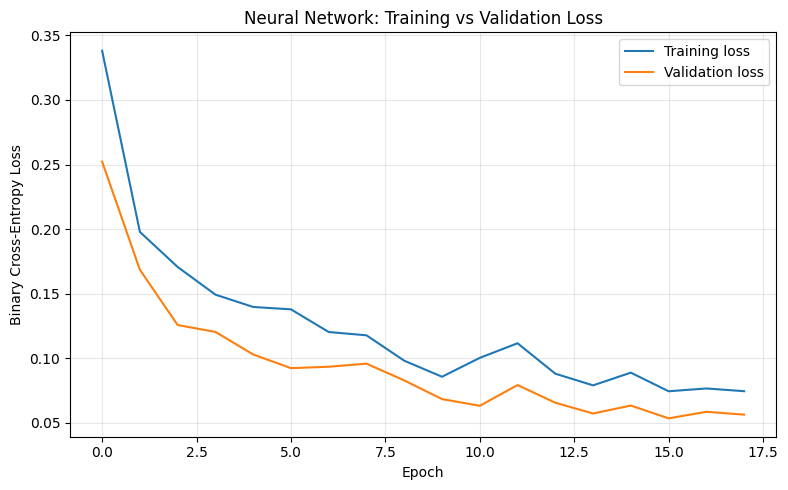

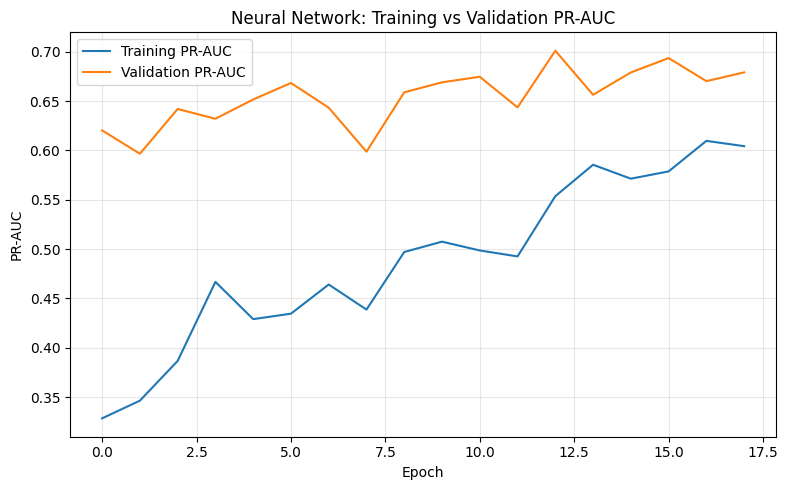

Learning curves saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/neural_network_20261017_202618/figures


In [79]:
# Loss curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history["loss"], label="Training loss")
ax.plot(history.history["val_loss"], label="Validation loss")
ax.set_title("Neural Network: Training vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary Cross-Entropy Loss")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    EXPERIMENT_FIGURES / "loss_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# PR-AUC curve
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history.history["pr_auc"], label="Training PR-AUC")
ax.plot(history.history["val_pr_auc"], label="Validation PR-AUC")
ax.set_title("Neural Network: Training vs Validation PR-AUC")
ax.set_xlabel("Epoch")
ax.set_ylabel("PR-AUC")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()

fig.savefig(
    EXPERIMENT_FIGURES / "pr_auc_learning_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Learning curves saved to:", EXPERIMENT_FIGURES)

,Model,Threshold,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Neural Network,0.9989,0.8169,0.8169,0.8169,0.9681,0.7061


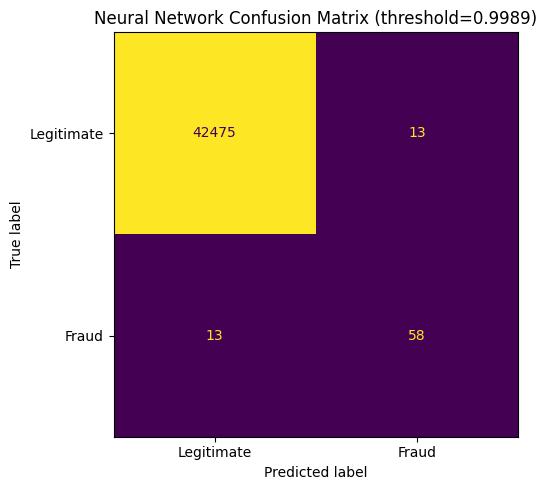

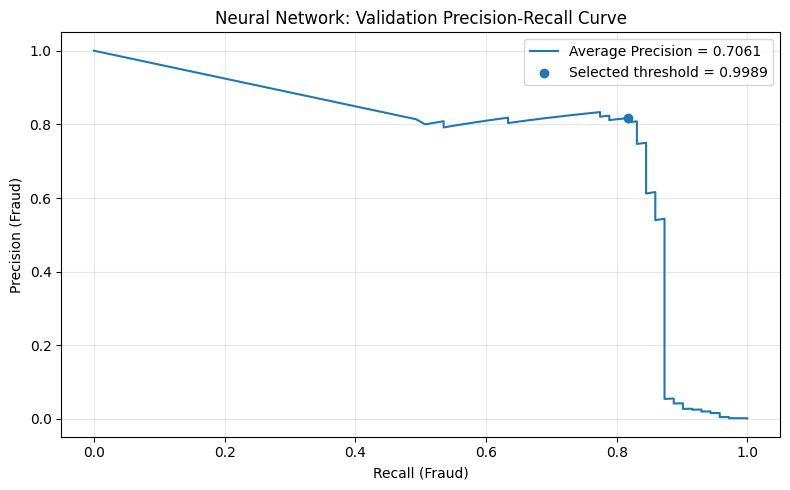

Validation metrics, predictions, threshold, and graphs saved.
Experiment folder: /content/drive/MyDrive/ML_Summative_Credit_Card/experiments/neural_network_20261017_202618


In [80]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

# Predict fraud probabilities using the restored best model.
val_probs_nn = nn_model.predict(X_val_nn, batch_size=1024, verbose=0).ravel()

# Calculate threshold-independent metrics.
val_roc_auc_nn = roc_auc_score(y_val_nn, val_probs_nn)
val_ap_nn = average_precision_score(y_val_nn, val_probs_nn)

# Find the threshold with the highest precision while maintaining >=80% recall.
precisions, recalls, thresholds = precision_recall_curve(
    y_val_nn.astype(int),
    val_probs_nn
)

target_recall = 0.80
eligible = np.where(recalls[:-1] >= target_recall)[0]

if len(eligible) == 0:
    raise ValueError(
        "No threshold reached the target recall. "
        "Inspect the precision-recall curve before proceeding."
    )

best_idx = eligible[np.argmax(precisions[eligible])]
nn_threshold = float(thresholds[best_idx])

val_preds_nn = (val_probs_nn >= nn_threshold).astype(int)

nn_metrics = {
    "Model": "Neural Network",
    "Threshold": nn_threshold,
    "Precision": precision_score(
        y_val_nn, val_preds_nn, zero_division=0
    ),
    "Recall": recall_score(
        y_val_nn, val_preds_nn, zero_division=0
    ),
    "F1-score": f1_score(
        y_val_nn, val_preds_nn, zero_division=0
    ),
    "ROC-AUC": val_roc_auc_nn,
    "Average Precision": val_ap_nn
}

nn_metrics_df = pd.DataFrame([nn_metrics])
display(nn_metrics_df.round(4))

# Save metrics and selected threshold.
nn_metrics_df.to_csv(
    EXPERIMENT_RESULTS / "validation_metrics.csv",
    index=False
)

with open(EXPERIMENT_RESULTS / "selected_threshold.json", "w") as f:
    json.dump({
        "target_recall": target_recall,
        "selected_threshold": nn_threshold,
        "selection_method": (
            "Highest precision among validation thresholds "
            "with recall >= 0.80"
        )
    }, f, indent=4)

# Save validation probabilities for reproducibility.
pd.DataFrame({
    "actual_class": y_val_nn.astype(int),
    "fraud_probability": val_probs_nn,
    "predicted_class": val_preds_nn
}).to_csv(
    EXPERIMENT_RESULTS / "validation_predictions.csv",
    index=False
)

# Save confusion matrix.
cm = confusion_matrix(y_val_nn.astype(int), val_preds_nn)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
).plot(ax=ax, values_format="d", colorbar=False)

ax.set_title(f"Neural Network Confusion Matrix (threshold={nn_threshold:.4f})")
fig.tight_layout()
fig.savefig(
    EXPERIMENT_FIGURES / "validation_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Save precision-recall curve.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(recalls, precisions, label=f"Average Precision = {val_ap_nn:.4f}")
ax.scatter(
    recalls[best_idx],
    precisions[best_idx],
    label=f"Selected threshold = {nn_threshold:.4f}"
)
ax.set_xlabel("Recall (Fraud)")
ax.set_ylabel("Precision (Fraud)")
ax.set_title("Neural Network: Validation Precision-Recall Curve")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(
    EXPERIMENT_FIGURES / "validation_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("Validation metrics, predictions, threshold, and graphs saved.")
print("Experiment folder:", EXPERIMENT_DIR)

In [82]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Compare models on the validation set.
# Use a common threshold of 0.5 for this first comparison.
validation_comparison = []

models_to_compare = {
    "Logistic Regression": (
        baseline_model,
        X_val_scaled
    ),
    "Random Forest (Baseline)": (
        rf_model,
        X_val
    ),
    "HistGradientBoosting": (
        hgb_model,
        X_val
    ),
}

for model_name, (model, X_val_input) in models_to_compare.items():
    probabilities = model.predict_proba(X_val_input)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    validation_comparison.append({
        "Model": model_name,
        "Threshold": 0.5,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(y_val, probabilities)
    })

# Neural network: use its validation probabilities at the same threshold.
nn_predictions_05 = (val_probs_nn >= 0.5).astype(int)

validation_comparison.append({
    "Model": "Neural Network",
    "Threshold": 0.5,
    "Precision": precision_score(y_val_nn, nn_predictions_05, zero_division=0),
    "Recall": recall_score(y_val_nn, nn_predictions_05, zero_division=0),
    "F1 Score": f1_score(y_val_nn, nn_predictions_05, zero_division=0),
    "ROC-AUC": roc_auc_score(y_val_nn, val_probs_nn),
    "Average Precision": average_precision_score(y_val_nn, val_probs_nn)
})

validation_comparison_df = pd.DataFrame(validation_comparison)

display(
    validation_comparison_df
    .sort_values("Average Precision", ascending=False)
    .round(4)
)

# Save the comparison in the current project folder.
comparison_path = PROJECT_DIR / "results" / "validation_model_comparison.csv"
comparison_path.parent.mkdir(parents=True, exist_ok=True)
validation_comparison_df.to_csv(comparison_path, index=False)

print(f"Validation comparison saved to: {comparison_path}")


,Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
1,Random Forest (Baseline),0.5,0.9355,0.8169,0.8722,0.9555,0.8593
2,HistGradientBoosting,0.5,0.5495,0.8592,0.6703,0.9751,0.7442
0,Logistic Regression,0.5,0.0611,0.9155,0.1145,0.9767,0.7217
3,Neural Network,0.5,0.0769,0.8732,0.1414,0.9681,0.7061


Validation comparison saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/results/validation_model_comparison.csv


In [83]:

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import numpy as np

threshold_candidates = {
    "Logistic Regression": (
        baseline_model.predict_proba(X_val_scaled)[:, 1],
        y_val
    ),
    "Random Forest (Baseline)": (
        rf_model.predict_proba(X_val)[:, 1],
        y_val
    ),
    "HistGradientBoosting": (
        hgb_model.predict_proba(X_val)[:, 1],
        y_val
    ),
    "Neural Network": (
        val_probs_nn,
        y_val_nn
    ),
}

threshold_results = []

for model_name, (probabilities, labels) in threshold_candidates.items():
    probabilities = np.asarray(probabilities).ravel()
    labels = np.asarray(labels).astype(int)

    precisions, recalls, thresholds = precision_recall_curve(
        labels, probabilities
    )

    # Keep thresholds that achieve at least 80% recall.
    eligible = np.where(recalls[:-1] >= 0.80)[0]

    if len(eligible) == 0:
        print(f"No threshold achieves 80% recall for {model_name}.")
        continue

    # Choose the eligible threshold with the highest precision.
    best_idx = eligible[np.argmax(precisions[eligible])]
    best_threshold = float(thresholds[best_idx])

    predictions = (probabilities >= best_threshold).astype(int)

    threshold_results.append({
        "Model": model_name,
        "Selected Threshold": best_threshold,
        "Precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "Recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            labels, predictions, zero_division=0
        )
    })

threshold_comparison_df = pd.DataFrame(threshold_results)

display(
    threshold_comparison_df
    .sort_values(
        ["Precision", "F1 Score"],
        ascending=False
    )
    .round(4)
)

threshold_path = PROJECT_DIR / "results" / "validation_threshold_comparison.csv"
threshold_path.parent.mkdir(parents=True, exist_ok=True)
threshold_comparison_df.to_csv(threshold_path, index=False)

print(f"Threshold comparison saved to: {threshold_path}")


,Model,Selected Threshold,Precision,Recall,F1 Score
1,Random Forest (Baseline),0.5931,0.9508,0.8169,0.8788
2,HistGradientBoosting,0.9955,0.8636,0.8028,0.8321
3,Neural Network,0.9989,0.8169,0.8169,0.8169
0,Logistic Regression,0.9999,0.7532,0.8169,0.7838


Threshold comparison saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/results/validation_threshold_comparison.csv


In [87]:

# Recover the tuned Random Forest from the existing variables.
if hasattr(best_rf_model, "best_estimator_"):
    tuned_rf_model = best_rf_model.best_estimator_
else:
    tuned_rf_model = best_rf_model

print("Tuned model:", type(tuned_rf_model).__name__)

# Compare baseline and tuned Random Forest on validation data.
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
import numpy as np
import pandas as pd

rf_finalists = {
    "Baseline Random Forest": rf_model,
    "Tuned Random Forest": tuned_rf_model
}

finalist_results = []

for name, model in rf_finalists.items():
    probabilities = model.predict_proba(X_val)[:, 1]

    precisions, recalls, thresholds = precision_recall_curve(
        y_val, probabilities
    )
    eligible = np.where(recalls[:-1] >= 0.80)[0]

    if len(eligible) == 0:
        print(f"No threshold achieved 80% recall for {name}.")
        continue

    best_idx = eligible[np.argmax(precisions[eligible])]
    threshold = float(thresholds[best_idx])
    predictions = (probabilities >= threshold).astype(int)

    finalist_results.append({
        "Model": name,
        "Threshold": threshold,
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions, zero_division=0),
        "F1 Score": f1_score(y_val, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Average Precision": average_precision_score(y_val, probabilities)
    })

finalist_df = pd.DataFrame(finalist_results)
display(finalist_df.round(4))

finalist_path = PROJECT_DIR / "results" / "random_forest_finalist_comparison.csv"
finalist_path.parent.mkdir(parents=True, exist_ok=True)
finalist_df.to_csv(finalist_path, index=False)

print(f"Saved to: {finalist_path}")


Tuned model: RandomForestClassifier


,Model,Threshold,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Baseline Random Forest,0.5931,0.9508,0.8169,0.8788,0.9555,0.8593
1,Tuned Random Forest,0.5797,0.9667,0.8169,0.8855,0.9491,0.8618


Saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/results/random_forest_finalist_comparison.csv


,Model,Threshold,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Average Precision
0,Tuned Random Forest,0.5797,0.9995,0.9615,0.7042,0.813,0.9415,0.8272



Classification report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     42488
       Fraud       0.96      0.70      0.81        71

    accuracy                           1.00     42559
   macro avg       0.98      0.85      0.91     42559
weighted avg       1.00      1.00      1.00     42559



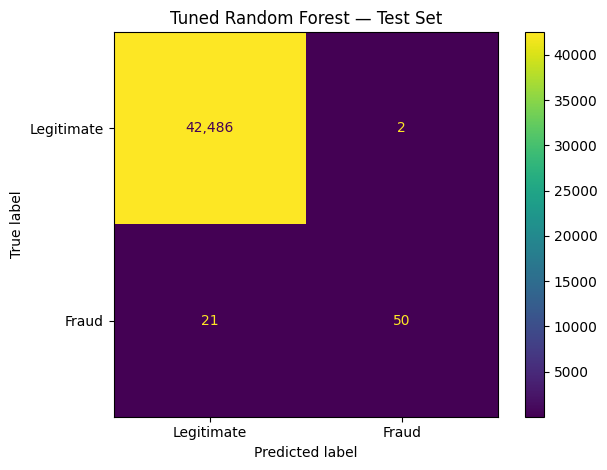


Final test artifacts saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/results/final_evaluation


In [88]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    accuracy_score
)
import matplotlib.pyplot as plt
import pandas as pd
import json

# Final model and threshold selected using validation data only.
final_model = tuned_rf_model
final_threshold = 0.5797

# Evaluate on the held-out test set for the first time.
test_probabilities = final_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= final_threshold).astype(int)

test_metrics = {
    "Model": "Tuned Random Forest",
    "Threshold": final_threshold,
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Precision": precision_score(y_test, test_predictions, zero_division=0),
    "Recall": recall_score(y_test, test_predictions, zero_division=0),
    "F1 Score": f1_score(y_test, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_probabilities),
    "Average Precision": average_precision_score(y_test, test_probabilities)
}

test_metrics_df = pd.DataFrame([test_metrics])
display(test_metrics_df.round(4))

print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, test_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)
disp.plot(values_format=",")
plt.title("Tuned Random Forest — Test Set")
plt.tight_layout()

test_figures_dir = PROJECT_DIR / "results" / "final_evaluation"
test_figures_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(
    test_figures_dir / "test_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Save test metrics and predictions.
test_metrics_df.to_csv(
    test_figures_dir / "test_metrics.csv",
    index=False
)

pd.DataFrame({
    "actual": y_test,
    "fraud_probability": test_probabilities,
    "predicted": test_predictions
}).to_csv(
    test_figures_dir / "test_predictions.csv",
    index=False
)

with open(test_figures_dir / "final_model_config.json", "w") as f:
    json.dump({
        "model": "Tuned Random Forest",
        "threshold": final_threshold,
        "threshold_selected_on": "validation set",
        "final_evaluation_set": "held-out test set"
    }, f, indent=2)

print(f"\nFinal test artifacts saved to: {test_figures_dir}")


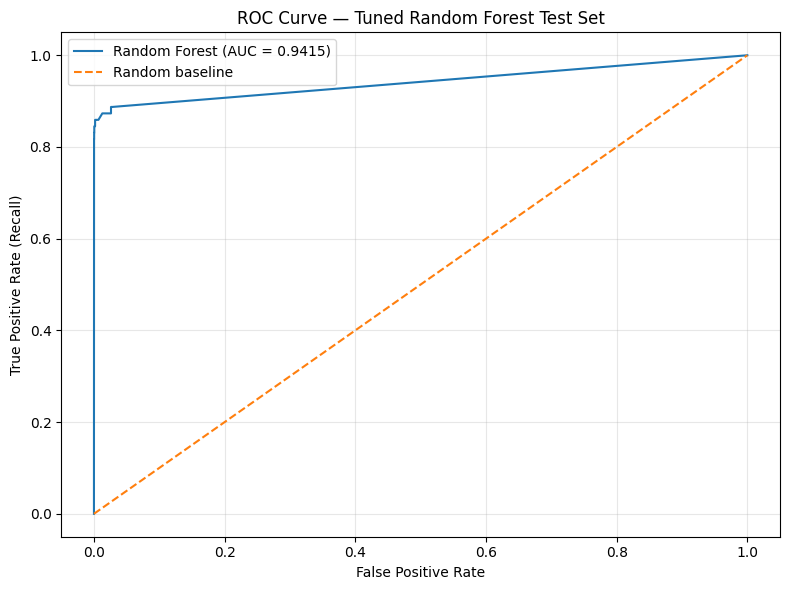

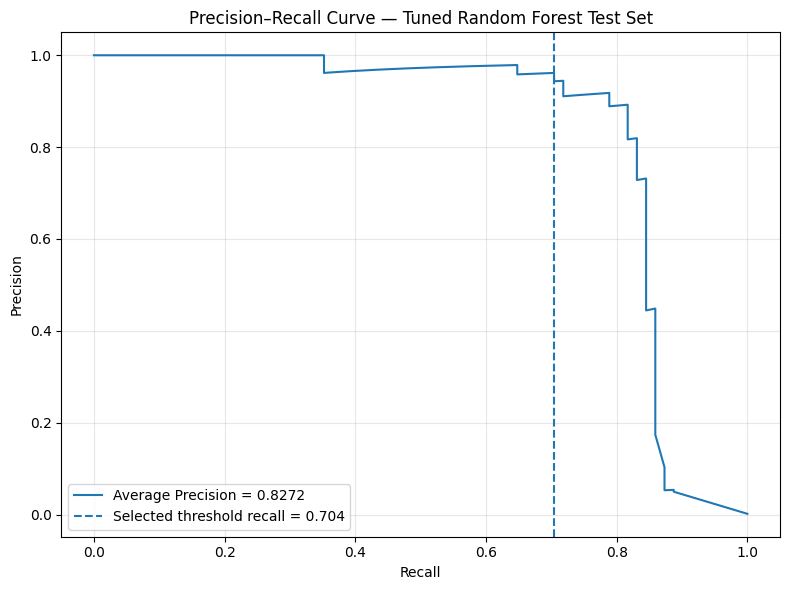

ROC-AUC: 0.9415
Average Precision: 0.8272
Plots saved to: /content/drive/MyDrive/ML_Summative_Credit_Card/results/final_evaluation


In [89]:

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)
import matplotlib.pyplot as plt

# Reuse predictions from the final test evaluation.
roc_fpr, roc_tpr, _ = roc_curve(y_test, test_probabilities)
test_roc_auc = roc_auc_score(y_test, test_probabilities)

pr_precision, pr_recall, _ = precision_recall_curve(
    y_test, test_probabilities
)
test_ap = average_precision_score(y_test, test_probabilities)

# Save both plots in the final evaluation folder.
test_figures_dir = PROJECT_DIR / "results" / "final_evaluation"
test_figures_dir.mkdir(parents=True, exist_ok=True)

# ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(roc_fpr, roc_tpr, label=f"Random Forest (AUC = {test_roc_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
ax.set_title("ROC Curve — Tuned Random Forest Test Set")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(test_figures_dir / "test_roc_curve.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Precision–Recall curve
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(pr_recall, pr_precision, label=f"Average Precision = {test_ap:.4f}")
ax.axvline(
    recall_score(y_test, test_predictions),
    linestyle="--",
    label=f"Selected threshold recall = {recall_score(y_test, test_predictions):.3f}"
)
ax.set_title("Precision–Recall Curve — Tuned Random Forest Test Set")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(
    test_figures_dir / "test_precision_recall_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print(f"ROC-AUC: {test_roc_auc:.4f}")
print(f"Average Precision: {test_ap:.4f}")
print(f"Plots saved to: {test_figures_dir}")


In [91]:

from pathlib import Path
import shutil
import json
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix

PROJECT_DIR = Path("/content/drive/MyDrive/ML_Summative_Credit_Card")
FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"
MODEL_DIR = FINAL_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# 1. Copy the tuned traditional ML model from the latest tuning run.
rf_source = (
    PROJECT_DIR / "experiments" / "rf_tuning_20261017_201037"
    / "models" / "best_random_forest.joblib"
)

if not rf_source.exists():
    raise FileNotFoundError(f"Tuned Random Forest file not found: {rf_source}")

shutil.copy2(rf_source, MODEL_DIR / "best_random_forest.joblib")

# 2. Copy the trained neural network and its scaler.
nn_source_dir = (
    PROJECT_DIR / "experiments" / "neural_network_20261017_202618"
    / "models"
)

for filename in ["neural_network.keras", "neural_network_scaler.joblib"]:
    source = nn_source_dir / filename
    if not source.exists():
        raise FileNotFoundError(f"Neural network artifact not found: {source}")
    shutil.copy2(source, MODEL_DIR / filename)

# 3. Save the final test classification report and confusion matrix.
report = classification_report(
    y_test,
    test_predictions,
    labels=[0, 1],
    target_names=["Legitimate", "Fraud"],
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    FINAL_DIR / "test_classification_report.csv",
    index=True
)

pd.DataFrame(
    confusion_matrix(y_test, test_predictions, labels=[0, 1]),
    index=["Actual legitimate", "Actual fraud"],
    columns=["Predicted legitimate", "Predicted fraud"]
).to_csv(FINAL_DIR / "test_confusion_matrix.csv")

# 4. Save the final traditional model's selected threshold and test metrics.
final_summary = {
    "selected_traditional_model": "Tuned Random Forest",
    "threshold": 0.5797,
    "threshold_selection": "Validation set",
    "test_metrics": test_metrics
}

with open(FINAL_DIR / "final_results_summary.json", "w") as f:
    json.dump(final_summary, f, indent=2)

# 5. Verify the final bundle.
print("FINAL MODEL BUNDLE")
for path in sorted(MODEL_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

print("\nFinal evaluation files:")
for path in sorted(FINAL_DIR.iterdir()):
    if path.is_file():
        print(path.name)

print("\nBundle prepared. No model training was performed.")


FINAL MODEL BUNDLE
best_random_forest.joblib: 2,735,513 bytes
neural_network.keras: 94,868 bytes
neural_network_scaler.joblib: 1,767 bytes

Final evaluation files:
final_model_config.json
final_results_summary.json
test_classification_report.csv
test_confusion_matrix.csv
test_confusion_matrix.png
test_metrics.csv
test_precision_recall_curve.png
test_predictions.csv
test_roc_curve.png

Bundle prepared. No model training was performed.
